<img src="https://raw.githubusercontent.com/amobionovo/EvidenceLab/main/lessons/08-deduplication-composite-key/assets/deduplication_thumbnail.png" width="800" style="max-width:100%;height:auto" alt="EvidenceLab Lesson 8 — When One Person Becomes Two, by Dr. Amobi Andrew Onovo. The same fictional woman appears in teal and yellow clothing across two record cards.">

**Dr. Amobi Andrew Onovo, PhD, MPH**  
Epidemiology | Data Science | AI for Global Health

# EvidenceLab #08: When One Person Becomes Two
## A beginner-friendly workflow for deduplication with composite keys and record linkage

**EvidenceLab | See it. Understand it. Run it.**

A dashboard can be correct. Your code can run perfectly. Your model can converge. Yet your conclusion can still be wrong if the underlying records contain duplicates.

This lesson uses **entirely synthetic data** to show how duplicate records arise, how to detect candidate duplicates, why a match is **a flag rather than a verdict**, and how adjudication protects against false matches.

---

## 👋 New to Google Colab? Start here

**You do not need to know Python or write any code to complete this lesson.**

Everything has already been prepared for you.

### ▶️ Run the entire lesson in one click

From the Google Colab menu at the top of this page:

**Runtime → Run all**

That's it.

Google Colab will automatically:

↳ create the synthetic dataset  
↳ clean and standardize the records  
↳ build the composite key  
↳ identify candidate duplicate records  
↳ calculate similarity scores  
↳ create the adjudication queue  
↳ generate the charts and tables  
↳ test different matching thresholds  
↳ compare results before and after deduplication  
↳ demonstrate how duplicates can affect a downstream model

Once execution finishes, simply **read the notebook from top to bottom** and follow the explanations, tables, and visualizations.

### What should I do when I see a code cell?

Nothing.

The code cells contain the instructions that perform the analysis. **Run all** executes them automatically in the correct order.

You are welcome to explore the code if you want to learn how the analysis works, but understanding Python is **not required to understand the lesson**.

> 💡 **EvidenceLab approach:** Focus first on *what we are doing, why we are doing it, and how to interpret the result*. The code is there when you are ready to go deeper.

---

## 🗺️ Your EvidenceLab #08 journey

**START**

↓

**1 | Understand the duplicate-record problem**

↓

**2 | Create the synthetic data**

↓

**3 | Check data quality**

↓

**4 | Clean and standardize the records**

↓

**5 | Build the composite key**

↓

**6 | Generate candidate matches**

↓

**7 | Score and review candidates**

↓

**8 | Adjudicate and resolve duplicates**

↓

**9 | Measure the impact of double counting**

↓

**10 | See what happens to a downstream model**

↓

**FINISH**

**No coding required. Just click `Runtime → Run all` and follow the story.**

---


### Learning objectives
By the end, you will be able to:
1. Explain why duplicate records matter.
2. Use **VIP-RT** as a practical data-quality memory framework: Validity, Integrity, Precision, Reliability, Timeliness.
3. Standardize messy records before matching.
4. Build and evaluate a composite key.
5. Use exact and fuzzy similarity to generate candidate matches.
6. Create a transparent review/adjudication queue.
7. Quantify how duplicates can change reported indicators.
8. Compare a downstream model before and after deduplication.

> **Privacy note:** Never publish identifiable client data. Use approved governance, minimum necessary fields, secure environments, and an approved SOP/protocol for real-world linkage.

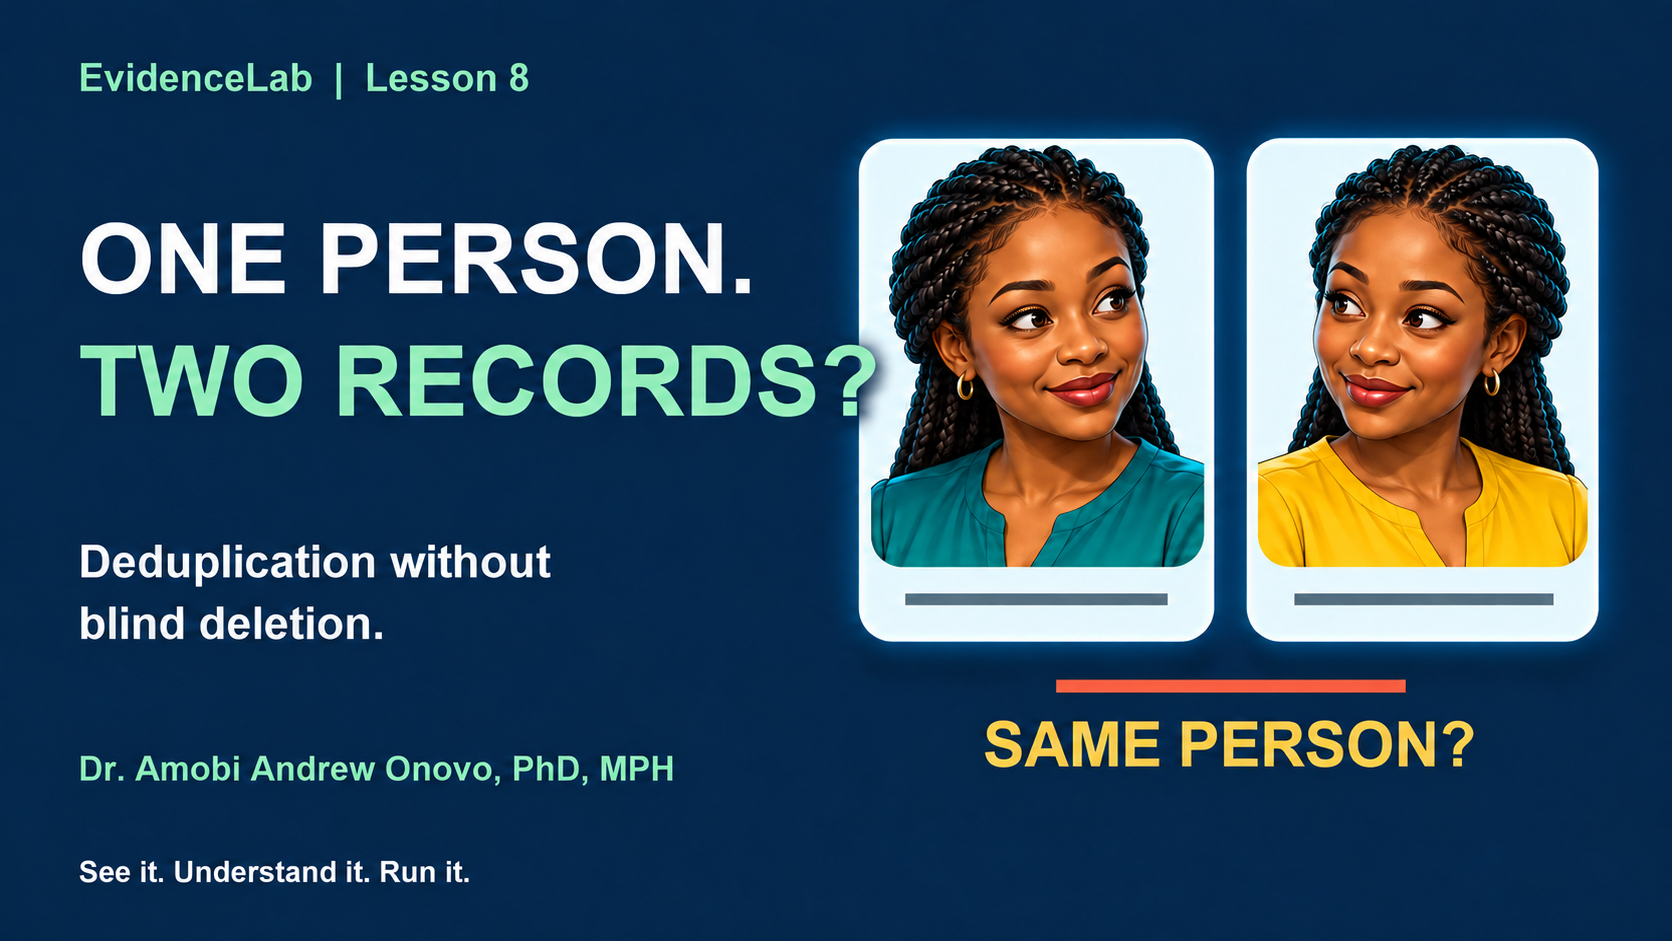

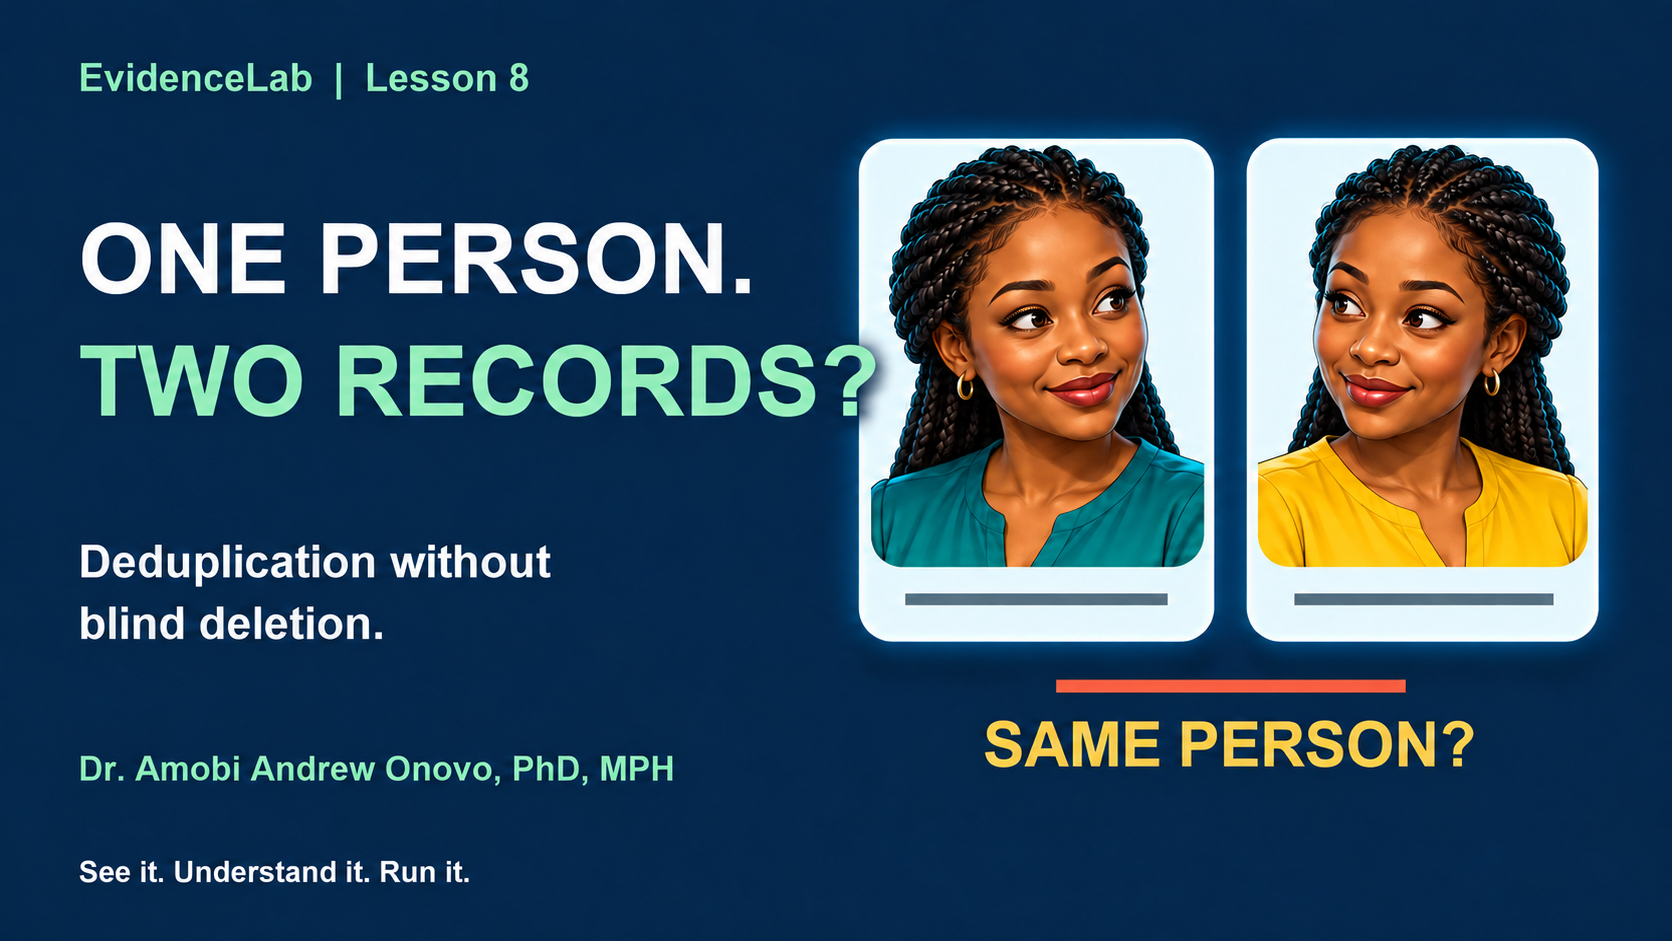

In [1]:
# @title Display the embedded lesson thumbnail
from IPython.display import Image, display
import base64
display(Image(data=base64.b64decode("..."), width=960))


In [ ]:
# Run once in Google Colab
%pip -q install "plotly>=6" rapidfuzz scikit-learn


In [2]:
import re, unicodedata, random
from datetime import date
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from rapidfuzz.fuzz import ratio
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

SEED = 808
rng = np.random.default_rng(SEED)
random.seed(SEED)
REFERENCE_DATE = pd.Timestamp("2026-10-01")
pd.set_option("display.max_columns", 50)

print("Ready. Random seed:", SEED)


Ready. Random seed: 808


## 1. Start with the data-quality question

Before building a model, ask whether the records are fit for purpose.

### VIP-RT
- **V — Validity:** Does the data represent what it is supposed to represent?
- **I — Integrity:** Has it remained complete and protected from inappropriate duplication or alteration?
- **P — Precision:** Is it recorded with sufficient specificity and consistency?
- **R — Reliability:** Would measurement remain consistent across systems, people, facilities, or time?
- **T — Timeliness:** Is it available when needed for decision-making?

For this lesson, we focus on a problem that can undermine several of these dimensions: **duplicate records**.


## 2. Create a synthetic population

We create unique people first, then deliberately introduce realistic data-quality problems: re-registration, facility transfer, spelling variation, phone formatting differences, and missingness.

Because we know the hidden `true_person_id`, we can objectively evaluate our matching algorithm. In real programs, that truth is usually established through approved adjudication and source-record review.


In [3]:
N_UNIQUE = 5000
first_names = np.array(["Amina","Ada","Chinedu","Fatima","Grace","Ibrahim","Joseph","Mary","Musa","Ngozi","Samuel","Zainab"])
last_names = np.array(["Okafor","Bello","Musa","Adeyemi","Nwosu","Ibrahim","Eze","Yusuf","Adebayo","Ali","Okeke","Garba"])
districts = np.array(["Central","North","South","East","West"])
facilities = np.array([f"Clinic {x}" for x in list("ABCDEFGH")])
sexes = np.array(["F","M"])

base = pd.DataFrame({
    "true_person_id": np.arange(1, N_UNIQUE+1),
    "first_name": rng.choice(first_names, N_UNIQUE),
    "last_name": rng.choice(last_names, N_UNIQUE),
    "sex": rng.choice(sexes, N_UNIQUE),
    "district": rng.choice(districts, N_UNIQUE),
    "facility": rng.choice(facilities, N_UNIQUE),
})
start = pd.Timestamp("1955-01-01").value // 10**9
end = pd.Timestamp("2008-12-31").value // 10**9
base["dob"] = pd.to_datetime(rng.integers(start, end, N_UNIQUE), unit="s").normalize()
base["phone"] = ["080" + "".join(rng.choice(list("0123456789"), 8)) for _ in range(N_UNIQUE)]
base["service_month"] = pd.to_datetime(rng.choice(pd.date_range("2026-01-01","2026-09-01",freq="MS"), N_UNIQUE))
base["risk_factor"] = rng.binomial(1, .35, N_UNIQUE)
base["outcome"] = rng.binomial(1, 1/(1+np.exp(-(-2 + 1.2*base["risk_factor"] + .25*(base["sex"]=="M")))))
base.head()


,true_person_id,first_name,last_name,sex,district,facility,dob,phone,service_month,risk_factor,outcome
0,1,Samuel,Okeke,M,West,Clinic A,1996-08-30,08095204563,2026-07-01,1,1
1,2,Ibrahim,Musa,M,South,Clinic C,1993-08-11,08061467768,2026-02-01,0,0
2,3,Ibrahim,Ali,M,West,Clinic G,1965-05-25,08092898524,2026-03-01,1,0
3,4,Grace,Eze,M,Central,Clinic H,1967-04-12,08094271789,2026-09-01,0,0
4,5,Fatima,Bello,F,North,Clinic H,1997-01-23,08061963110,2026-06-01,0,1


In [4]:
# Inject duplicate registrations for ~12% of people
dup_ids = rng.choice(base.index, size=int(N_UNIQUE*0.12), replace=False)
dups = base.loc[dup_ids].copy()
dups["facility"] = rng.choice(facilities, len(dups))

def typo(s):
    s = str(s)
    if len(s) < 4: return s
    i = random.randrange(len(s)-1)
    return s[:i] + s[i+1] + s[i] + s[i+2:]

for idx in rng.choice(dups.index, size=int(len(dups)*0.35), replace=False):
    dups.loc[idx, "last_name"] = typo(dups.loc[idx, "last_name"])
for idx in rng.choice(dups.index, size=int(len(dups)*0.30), replace=False):
    dups.loc[idx, "phone"] = "+234" + str(dups.loc[idx, "phone"])[1:]
for idx in rng.choice(dups.index, size=int(len(dups)*0.12), replace=False):
    dups.loc[idx, "phone"] = np.nan
for idx in rng.choice(dups.index, size=int(len(dups)*0.08), replace=False):
    dups.loc[idx, "district"] = np.nan

df = pd.concat([base, dups], ignore_index=True)
df.insert(0, "record_id", [f"R{i:05d}" for i in range(1, len(df)+1)])

print(f"Rows reported: {len(df):,}")
print(f"True unique people: {df.true_person_id.nunique():,}")
print(f"Extra duplicate records: {len(df)-df.true_person_id.nunique():,}")
df.sample(8, random_state=SEED)


Rows reported: 5,600
True unique people: 5,000
Extra duplicate records: 600


,record_id,true_person_id,first_name,last_name,sex,district,facility,dob,phone,service_month,risk_factor,outcome
4677,R04678,4678,Zainab,Musa,F,North,Clinic H,2003-04-15,08081168638,2026-02-01,0,0
308,R00309,309,Chinedu,Adebayo,F,South,Clinic E,1975-08-25,08051465064,2026-03-01,0,0
1237,R01238,1238,Ngozi,Adeyemi,M,East,Clinic C,1978-11-06,08090779588,2026-06-01,1,0
3291,R03292,3292,Fatima,Ibrahim,F,West,Clinic H,2002-05-12,08011460365,2026-07-01,0,0
4186,R04187,4187,Ada,Ali,F,East,Clinic D,2000-04-04,08040472107,2026-02-01,1,0
3517,R03518,3518,Zainab,Yusuf,F,Central,Clinic C,1986-09-08,08068765043,2026-03-01,0,0
66,R00067,67,Mary,Adeyemi,F,Central,Clinic D,1957-10-18,08082858060,2026-02-01,1,0
4674,R04675,4675,Ibrahim,Ali,M,Central,Clinic A,2000-03-06,08072591109,2026-04-01,1,1


## 3. Profile data quality before matching

Good deduplication starts with understanding the data, not with choosing a matching threshold.


In [5]:
profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_n": df.isna().sum(),
    "missing_pct": (df.isna().mean()*100).round(2),
    "unique_values": df.nunique(dropna=True)
}).sort_values("missing_pct", ascending=False)
profile


,dtype,missing_n,missing_pct,unique_values
phone,str,72,1.29,5155
district,str,48,0.86,5
record_id,str,0,0.00,5600
true_person_id,int64,0,0.00,5000
last_name,str,0,0.00,57
first_name,str,0,0.00,12
facility,str,0,0.00,8
sex,str,0,0.00,2
dob,datetime64[s],0,0.00,4423
service_month,datetime64[us],0,0.00,9


In [6]:
missing = profile.reset_index(names="variable")
fig = px.bar(missing, x="variable", y="missing_pct",
             title="Missingness by variable", labels={"missing_pct":"Missing (%)","variable":""})
fig.show()


## 4. Standardize before you compare

The same person can look different because of capitalization, punctuation, spaces, phone prefixes, or inconsistent coding. Standardization reduces artificial disagreement.


In [7]:
def norm_text(x):
    if pd.isna(x): return ""
    x = unicodedata.normalize("NFKD", str(x)).encode("ascii","ignore").decode()
    x = re.sub(r"[^A-Za-z0-9]", "", x).upper()
    return x

def norm_phone(x):
    if pd.isna(x): return ""
    digits = re.sub(r"\D", "", str(x))
    if digits.startswith("234") and len(digits) >= 13:
        digits = "0" + digits[3:]
    return digits[-11:]

work = df.copy()
for c in ["first_name","last_name","sex","district","facility"]:
    work[c+"_std"] = work[c].map(norm_text)
work["phone_std"] = work["phone"].map(norm_phone)
work["dob_std"] = pd.to_datetime(work["dob"]).dt.strftime("%Y%m%d")

work[["record_id","first_name","first_name_std","last_name","last_name_std","phone","phone_std"]].sample(8, random_state=8)


,record_id,first_name,first_name_std,last_name,last_name_std,phone,phone_std
3977,R03978,Samuel,SAMUEL,Bello,BELLO,08043529946,08043529946
2413,R02414,Ada,ADA,Musa,MUSA,08010285089,08010285089
2236,R02237,Amina,AMINA,Bello,BELLO,08063529149,08063529149
3795,R03796,Ada,ADA,Adeyemi,ADEYEMI,08057862691,08057862691
4664,R04665,Ibrahim,IBRAHIM,Adebayo,ADEBAYO,08058142495,08058142495
2946,R02947,Joseph,JOSEPH,Eze,EZE,08021449631,08021449631
760,R00761,Fatima,FATIMA,Adebayo,ADEBAYO,08050347777,08050347777
496,R00497,Chinedu,CHINEDU,Yusuf,YUSUF,08075742868,08075742868


## 5. Build a composite key

A composite key combines selected fields when no reliable universal identifier exists.

For teaching, we start with:

`DOB + Sex + District`

**Important:** identical composite keys create **candidate groups**. They do **not** prove that records belong to the same person.


In [8]:
work["composite_key"] = (
    work["dob_std"] + "|" + work["sex_std"] + "|" + work["district_std"]
)
work["key_group_size"] = work.groupby("composite_key")["record_id"].transform("size")
work["candidate_by_key"] = work["key_group_size"] > 1

work["candidate_by_key"].value_counts().rename_axis("flag").to_frame("records")


,records
flag,
False,4388
True,1212


In [9]:
summary = work["candidate_by_key"].value_counts().rename_axis("status").reset_index(name="records")
fig = px.bar(summary, x="status", y="records", text="records",
             title="Records flagged by the composite key")
fig.show()


## 6. Generate candidate pairs inside blocks

Blocking avoids comparing every record with every other record. Here, records sharing the composite key become candidate pairs.


In [10]:
from itertools import combinations

pairs = []
for key, g in work.groupby("composite_key"):
    if len(g) < 2: continue
    for a,b in combinations(g.index, 2):
        ra, rb = work.loc[a], work.loc[b]
        pairs.append({
            "idx_a": a, "idx_b": b,
            "record_a": ra.record_id, "record_b": rb.record_id,
            "true_match": int(ra.true_person_id == rb.true_person_id),
            "first_sim": ratio(ra.first_name_std, rb.first_name_std)/100,
            "last_sim": ratio(ra.last_name_std, rb.last_name_std)/100,
            "phone_exact": int(bool(ra.phone_std) and ra.phone_std == rb.phone_std),
            "facility_same": int(ra.facility_std == rb.facility_std)
        })

pairs = pd.DataFrame(pairs)
print("Candidate pairs:", len(pairs))
pairs.head()


Candidate pairs: 627


,idx_a,idx_b,record_a,record_b,true_match,first_sim,last_sim,phone_exact,facility_same
0,1931,5489,R01932,R05490,1,1.000000,1.000000,1,1
1,3351,5144,R03352,R05145,1,1.000000,1.000000,1,0
2,2749,5402,R02750,R05403,1,1.000000,1.000000,1,0
3,1075,2771,R01076,R02772,0,0.200000,0.166667,0,0
4,233,1903,R00234,R01904,0,0.727273,0.181818,0,0


## 7. Score the candidates

This transparent teaching score combines name similarity and phone agreement. A production linkage model should be validated for its setting and governed by an approved protocol.


In [11]:
if len(pairs):
    pairs["match_score"] = (
        0.30*pairs["first_sim"] +
        0.40*pairs["last_sim"] +
        0.30*pairs["phone_exact"]
    )
    pairs["review_band"] = pd.cut(
        pairs["match_score"],
        bins=[-0.01,0.69,0.89,1.01],
        labels=["Unlikely match","Possible match","High-confidence candidate"]
    )
pairs.sort_values("match_score", ascending=False).head(12)


,idx_a,idx_b,record_a,record_b,true_match,first_sim,last_sim,phone_exact,facility_same,match_score,review_band
5,2485,5376,R02486,R05377,1,1.0,1.0,1,0,1.0,High-confidence candidate
626,4487,5177,R04488,R05178,1,1.0,1.0,1,1,1.0,High-confidence candidate
0,1931,5489,R01932,R05490,1,1.0,1.0,1,1,1.0,High-confidence candidate
1,3351,5144,R03352,R05145,1,1.0,1.0,1,0,1.0,High-confidence candidate
623,1537,5067,R01538,R05068,1,1.0,1.0,1,0,1.0,High-confidence candidate
624,4221,5492,R04222,R05493,1,1.0,1.0,1,0,1.0,High-confidence candidate
625,844,5459,R00845,R05460,1,1.0,1.0,1,0,1.0,High-confidence candidate
2,2749,5402,R02750,R05403,1,1.0,1.0,1,0,1.0,High-confidence candidate
378,1210,5358,R01211,R05359,1,1.0,1.0,1,0,1.0,High-confidence candidate
379,4226,5086,R04227,R05087,1,1.0,1.0,1,0,1.0,High-confidence candidate


In [12]:
fig = px.histogram(pairs, x="match_score", color="true_match", nbins=30,
                   title="Candidate match-score distribution",
                   labels={"match_score":"Match score","true_match":"Known synthetic truth"})
fig.show()


## 8. Threshold sensitivity: precision and recall

There is no universally correct threshold. A lower threshold may catch more duplicates but also create more false matches. A higher threshold may be more precise but miss true duplicates.


These metrics are conditional on pairs surviving blocking. End-to-end recall must also count true duplicate pairs excluded by the key.


In [13]:
thresholds = np.round(np.linspace(0.50, 1.00, 11), 2)
metrics = []
for t in thresholds:
    pred = (pairs.match_score >= t).astype(int)
    metrics.append({
        "threshold": round(float(t),2),
        "precision": precision_score(pairs.true_match,pred,zero_division=0),
        "recall": recall_score(pairs.true_match,pred,zero_division=0),
        "f1": f1_score(pairs.true_match,pred,zero_division=0)
    })
metrics = pd.DataFrame(metrics)
metrics


,threshold,precision,recall,f1
0,0.50,1.0,1.000000,1.000000
1,0.55,1.0,1.000000,1.000000
2,0.60,1.0,1.000000,1.000000
3,0.65,1.0,0.980072,0.989936
4,0.70,1.0,0.980072,0.989936
5,0.75,1.0,0.880435,0.936416
6,0.80,1.0,0.880435,0.936416
7,0.85,1.0,0.880435,0.936416
8,0.90,1.0,0.880435,0.936416
9,0.95,1.0,0.625000,0.769231


In [14]:
# Include true pairs missed during blocking in end-to-end recall.
true_pair_total = sum(k*(k-1)//2 for k in work.groupby("true_person_id").size())
blocking_true_pairs = int(pairs["true_match"].sum())
print(f"Blocking recall: {blocking_true_pairs / true_pair_total:.1%}")
metrics["end_to_end_recall"] = [
    int(((pairs.match_score >= t) & pairs.true_match.eq(1)).sum()) / true_pair_total
    for t in metrics.threshold
]
metrics


Blocking recall: 92.0%


,threshold,precision,recall,f1,end_to_end_recall
0,0.50,1.0,1.000000,1.000000,0.920000
1,0.55,1.0,1.000000,1.000000,0.920000
2,0.60,1.0,1.000000,1.000000,0.920000
3,0.65,1.0,0.980072,0.989936,0.901667
4,0.70,1.0,0.980072,0.989936,0.901667
5,0.75,1.0,0.880435,0.936416,0.810000
6,0.80,1.0,0.880435,0.936416,0.810000
7,0.85,1.0,0.880435,0.936416,0.810000
8,0.90,1.0,0.880435,0.936416,0.810000
9,0.95,1.0,0.625000,0.769231,0.575000


In [15]:
long = metrics.melt("threshold", var_name="metric", value_name="value")
fig = px.line(long, x="threshold", y="value", color="metric", markers=True,
              title="How the matching threshold changes performance")
fig.show()


## 9. Build the human adjudication queue

**A match is a flag, not a verdict.**

For this synthetic demonstration we use a threshold to create a review queue. In real work, reviewers should follow the approved SOP, inspect permitted source information, document the decision, and preserve an audit trail.


In [16]:
THRESHOLD = 0.80
queue = pairs.loc[pairs.match_score >= THRESHOLD].copy()
queue["review_status"] = "Needs review"
# Simulation only: hidden truth supplies labels, not a real human review.
queue["simulated_adjudication"] = np.where(queue.true_match.eq(1),"Confirmed duplicate","Not duplicate")
queue = queue.sort_values("match_score", ascending=False)

queue[["record_a","record_b","first_sim","last_sim","phone_exact","match_score","review_band","review_status","simulated_adjudication"]].head(20)


,record_a,record_b,first_sim,last_sim,phone_exact,match_score,review_band,review_status,simulated_adjudication
626,R04488,R05178,1.0,1.0,1,1.0,High-confidence candidate,Needs review,Confirmed duplicate
0,R01932,R05490,1.0,1.0,1,1.0,High-confidence candidate,Needs review,Confirmed duplicate
1,R03352,R05145,1.0,1.0,1,1.0,High-confidence candidate,Needs review,Confirmed duplicate
2,R02750,R05403,1.0,1.0,1,1.0,High-confidence candidate,Needs review,Confirmed duplicate
5,R02486,R05377,1.0,1.0,1,1.0,High-confidence candidate,Needs review,Confirmed duplicate
7,R01115,R05108,1.0,1.0,1,1.0,High-confidence candidate,Needs review,Confirmed duplicate
605,R01846,R05088,1.0,1.0,1,1.0,High-confidence candidate,Needs review,Confirmed duplicate
604,R04195,R05276,1.0,1.0,1,1.0,High-confidence candidate,Needs review,Confirmed duplicate
601,R04990,R05153,1.0,1.0,1,1.0,High-confidence candidate,Needs review,Confirmed duplicate
600,R02505,R05301,1.0,1.0,1,1.0,High-confidence candidate,Needs review,Confirmed duplicate


## 10. Resolve confirmed duplicates without destroying the raw data

Never overwrite your source file. Create a resolved analytical dataset and retain the audit trail.


The next cell is an **oracle benchmark**, using hidden synthetic truth. It is not a claim that our candidate workflow found every duplicate. In production, resolve only adjudicated links using a documented survivorship policy.


In [17]:
# ORACLE BENCHMARK ONLY: hidden synthetic truth resolves ALL duplicates.
# This is not the output of the threshold/review queue above.
resolved = work.sort_values(["true_person_id","record_id"]).drop_duplicates("true_person_id", keep="first").copy()

reported_n = len(work)
unique_n = len(resolved)
extra_records = reported_n - unique_n
overcount_relative_unique = extra_records / unique_n * 100

impact = pd.DataFrame({
    "Measure":["Reported records","Unique individuals","Extra duplicate records","Apparent overcount (%)"],
    "Value":[reported_n, unique_n, extra_records, round(overcount_relative_unique,1)]
})
impact


,Measure,Value
0,Reported records,5600.0
1,Unique individuals,5000.0
2,Extra duplicate records,600.0
3,Apparent overcount (%),12.0


In [18]:
counts = pd.DataFrame({
    "Dataset":["Before deduplication","Oracle unique-person benchmark"],
    "Records":[len(work),len(resolved)]
})
fig = px.bar(counts, x="Dataset", y="Records", text="Records",
             title="Reported volume before and after deduplication")
fig.show()


## 11. Slice the duplicate burden

Where are candidate or confirmed duplicates concentrated? Dynamic visualizations can help teams prioritize investigation.

These are within-facility extra records. A person counted once at each of two facilities does not create an extra record within either facility; totals across facilities are not a count of unique people.


In [19]:
truth_counts = work.groupby("facility", as_index=False).agg(
    reported_records=("record_id","size"),
    unique_people=("true_person_id","nunique")
)
truth_counts["extra_records"] = truth_counts["reported_records"] - truth_counts["unique_people"]
truth_counts["duplicate_burden_pct"] = 100*truth_counts["extra_records"]/truth_counts["unique_people"]

fig = px.bar(truth_counts, x="facility", y="duplicate_burden_pct", text_auto=".1f",
             title="Synthetic duplicate burden by facility",
             labels={"duplicate_burden_pct":"Extra records per 100 unique people (%)","facility":""})
fig.show()


## 12. Why data quality can change a downstream model

To make the point visible, we compare a simple prediction model on the duplicated analytical file with the deduplicated file. This is an illustration, not a clinical model.


AUC below is measured on the training data for illustration, not held-out predictive performance. Duplicate people should remain in the same split during model validation.


In [20]:
def model_result(data, label):
    X = pd.DataFrame({
        "risk_factor": data["risk_factor"].astype(int),
        "male": (data["sex"]=="M").astype(int)
    })
    y = data["outcome"].astype(int)
    m = LogisticRegression().fit(X,y)
    p = m.predict_proba(X)[:,1]
    return {
        "dataset":label,
        "n":len(data),
        "coef_risk_factor":m.coef_[0][0],
        "coef_male":m.coef_[0][1],
        "auc":roc_auc_score(y,p)
    }

model_compare = pd.DataFrame([
    model_result(work,"Duplicated records"),
    model_result(resolved,"Deduplicated records")
])
model_compare


,dataset,n,coef_risk_factor,coef_male,auc
0,Duplicated records,5600,1.079730,0.137954,0.636188
1,Deduplicated records,5000,1.120506,0.129370,0.641346


In [21]:
coef = model_compare.melt(id_vars=["dataset"], value_vars=["coef_risk_factor","coef_male"],
                          var_name="coefficient", value_name="estimate")
fig = px.bar(coef, x="coefficient", y="estimate", color="dataset", barmode="group",
             title="Illustration: duplicates can change downstream model estimates")
fig.show()


## 13. Exact matching when a reliable identifier exists

If a program has a governed, reliable universal identifier such as an approved national ID or biometric-derived identifier, exact matching can be incorporated into the workflow.

That does **not** eliminate the need for governance or quality checks: identifiers can still be missing, mistyped, duplicated, or linked incorrectly.

### General workflow

**CO-DESIGN → STANDARDIZE → BUILD/BLOCK → COMPARE → FLAG → ADJUDICATE → RESOLVE → AUDIT**


## 14. Cross-sector transfer

The same question appears outside health:

- **E-commerce:** Are three customer accounts three customers, or one customer represented three ways?
- **Education:** Is a transferring student being counted twice?
- **Finance:** Did multiple onboarding channels create duplicate customer profiles?
- **Humanitarian assistance:** Is one beneficiary represented in multiple distribution lists?
- **Government:** Are population or service records duplicated across administrative systems?

The central question is:

> **Are these two records two entities, or two representations of the same entity?**


## 15. Beginner challenge

Try changing `THRESHOLD` to **0.70, 0.85, 0.90, and 0.95**.

1. How does the number of candidate matches change?
2. What happens to precision?
3. What happens to recall?
4. Which errors would be more costly in your use case: false matches or missed duplicates?

### Key takeaway

**Do not stop at finding duplicates. Understand why they occurred, verify them, adjudicate them, and ensure the final analysis is based on accurate, unique records.**

**Better data → Better analysis → Better models → Better decisions.**

Compare candidate-pair recall with **end-to-end recall**. The latter also includes true duplicate pairs missed during blocking. Rerun the review-queue cell after changing `THRESHOLD`.
